In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM


/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [4]:
import pandas as pd
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
from scipy.sparse import save_npz, load_npz, csr_matrix

#task_id = int(os.environ['SLURM_ARRAY_TASK_ID'])

from bwm_functions import *


In [17]:
# MAIN LOOP
device = 'cpu'

# Get a list of all items (files and folders) in the directory

directory_path = 'Data'
all_items = os.listdir(directory_path)
print(len(all_items))
# Filter the list to include only folders (directories)
folders_only = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]
#eids = np.load("eids.npy",allow_pickle=True)

#
eid = random.choice(folders_only)
eid = "9fcbd1a0-77e6-4c41-9428-eeaee74becd5"
#eid = "25d1920e-a2af-4b6c-9f2e-fc6c65576544"
# eid = random.choice(eids)
full_path_to_random_folder = os.path.join(directory_path, eid)
print(f"Randomly selected eid: {full_path_to_random_folder}")


460
Randomly selected eid: Data/9fcbd1a0-77e6-4c41-9428-eeaee74becd5


In [18]:




# for _ in range(1):

dim = 5
sample_size = 50
sigma = 10
latent_dim = 25
hidden_dim = 30
n_steps = 100

threshold = 1
min_trials_per_condition  = 100
# Check if any folders were found

# Select a random folder name from the list

event = random.choice(["goCueTrigger_times","stimOff_times", "firstMovement_times", "goCue_times", "response_times","feedback_times","stimOn_times"])
event = "stimOn_times"
#event = random.choice(["firstMovement_times","feedback_times","stimOn_times"])
#conditions = list(np.random.choice(["choice","prev_choice","side","prev_side","reward","prev_reward"],size = np.random.choice([1,2,3]),replace = False))
conditions =  ['reward','prev_reward']

#conditions = ["choice","side"]
# Construct the full path to the randomly selected folder

clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')

clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Cosmos")

spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

#  responses = get_aligned_response_matrix(spikes, trials[event],stride=.005, step=.005, n_steps=100,sigma = 10)
counts_series = clusters.groupby('cosmos').size()
print(counts_series)


# shape n_pseudo x n_conditions x time x n
response_matrix_train,condition_matrix_train, response_matrix_test, condition_matrix_test = get_aligned_response_matrix(spikes, clusters, trials, event, conditions, stride=.0025, step=.0025,
                                            n_steps=n_steps,sigma = sigma, threshold = threshold, min_trials_per_condition = min_trials_per_condition)


print(response_matrix_test.shape)
# Restrict to good neurons:
# sub_sample = np.logical_and(np.mean(response_matrix_train, axis=(0, 1, 2)) > threshold,np.mean(response_matrix_test, axis=(0, 1,2)) > threshold)
# response_matrix_test = response_matrix_test[:, :, :, sub_sample]
# response_matrix_train = response_matrix_train[:, :, :, sub_sample]
response_matrix_test = response_matrix_test[:, :,:, np.mean(np.std(response_matrix_train, axis=0), axis=(0, 1))>.5]
response_matrix_train = response_matrix_train[:, :,:, np.mean(np.std(response_matrix_train, axis=0), axis=(0, 1))>.5]
n_neurons  = response_matrix_train.shape[3]
print(n_neurons)
# Choose random 50 neurons from 100 most active
#neuron_indices = np.argsort(np.mean(response_matrix_train, axis=(0, 1)))[-sample_size:]

neuron_indices = np.random.choice(n_neurons, sample_size, replace=False)

response_matrix_test = response_matrix_test[:, :,:, neuron_indices]
response_matrix_train = response_matrix_train[:, :,:, neuron_indices]
# responses_test = responses_test[:, :, neuron_indices]
# mean_responses_test = mean_responses_test[:, :, neuron_indices]
means = np.mean(response_matrix_train, axis=(0,1,2))

# Z-score single neuron responses
response_matrix_train = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2), keepdims=True)) / np.std(response_matrix_train, axis=(0, 1, 2), keepdims=True)
response_matrix_test = (response_matrix_test - np.mean(response_matrix_test, axis=(0, 1, 2), keepdims=True)) / np.std(response_matrix_test, axis=(0, 1, 2), keepdims=True)
#     responses_test = (responses_test - np.mean(responses_test, axis=(0, 1), keepdims=True)) / np.std(responses_test, axis=(0, 1),
#                                                                                       keepdims=True)
#     mean_responses_test = (mean_responses_test - np.mean(mean_responses_test, axis=(0, 1), keepdims=True)) / np.std(
#         mean_responses_test, axis=(0, 1), keepdims=True)
# #
# mean_responses_train = np.mean(response_matrix_train, axis=0, keepdims=True)
# # pca_error = compute_pca_error(mean_responses_train.reshape(-1, mean_responses_train.shape[2]), dim)
# pca = PCA().fit(mean_responses_train.reshape(-1, mean_responses_train.shape[2]))
# pca_error =  np.sum(pca.explained_variance_ratio_[dim:])
# pca_1 = np.sum(pca.explained_variance_ratio_[1:])
#
#
# kmeans_error = compute_kmeans_error(dim, mean_responses_train.reshape(-1, mean_responses_train.shape[2]).T)

response_matrix_train = torch.tensor(response_matrix_train).float().to(device)
response_matrix_test = torch.tensor(response_matrix_test).float().to(device)
# mean_responses = torch.tensor(mean_responses).float().to(device)
condition_matrix_train = torch.tensor(condition_matrix_train).float().to(device)
condition_matrix_test = torch.tensor(condition_matrix_test).float().to(device)

# train_indices = np.random.choice(len(responses), int(.8 * responses.shape[0]), replace=False)
# test_indices = list(set(range(len(responses))) - set(train_indices))
# test_indices = train_indices





cosmos
CNU     52
root    47
dtype: int64
(500, 1, 100, 76)
69


In [343]:
y_train = response_matrix_train.reshape(-1,response_matrix_train.shape[2],response_matrix_train.shape[3])
y_test = response_matrix_test.reshape(-1,response_matrix_train.shape[2],response_matrix_train.shape[3])
condition_train = condition_matrix_train.reshape(-1,condition_matrix_train.shape[2])
condition_test = condition_matrix_test.reshape(-1,condition_matrix_train.shape[2])

# Fit Linear model
linear_model = LinearNet(n=y_train.shape[2], latent_dim=latent_dim, hidden_dim = hidden_dim, n_conditions = condition_train.shape[1]).to(
    device)
linear_model.fit(steps=y_train.shape[1], epochs=1000, batch_size=100, lr=.001, verbose=True,
                 weight_decay=0., y_train=y_train,
                 y_test=y_test,conditions_train = condition_train, conditions_test = condition_test)
# linear_test_loss = linear_model.evaluate(condition_test,y_test, y_test.shape[1])
#test_linear_loss = linear_model.evaluate( condition_test,y_test, n_steps)
#train_linear_loss = linear_model.evaluate(  condition_train,y_train,n_steps)

mean_responses = torch.mean(response_matrix_train, dim=0)
mean_conditions = torch.mean(condition_matrix_train, dim=0)
train_linear_loss = linear_model.evaluate(mean_conditions, mean_responses, 100)

mean_responses = torch.mean(response_matrix_test, dim=0)
mean_conditions = torch.mean(condition_matrix_test, dim=0)
test_linear_loss = linear_model.evaluate(mean_conditions, mean_responses, 100)
linear_loss = linear_model.evaluate(condition_matrix, responses, n_steps)


KeyboardInterrupt: 

In [19]:
mean_responses = torch.mean(response_matrix_train, dim=0)
mean_conditions = torch.mean(condition_matrix_train, dim=0)
#linear_model.evaluate(mean_conditions, mean_responses, 100)

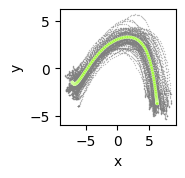

In [20]:

pca = PCA().fit(response_matrix_train.reshape(-1,response_matrix_train.shape[3]))
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
#
for i in range(100):
    for j in range(response_matrix_train.shape[1]):
        trajectory = pca.transform(response_matrix_train[i,j,:])
        sns.scatterplot(x=trajectory[:,0], y=trajectory[:,1], color='gray',alpha = .5,lw=0,ax=ax,s=1)
#
# for i in range(condition_matrix_train.shape[1]):
#
#     trajectory = pca.transform(torch.mean(response_matrix_train[:,i,:,],axis=0))
#     ax.plot(trajectory[:,0], trajectory[:,1], color='k',alpha = .5,lw=.5)
    #
# for condition in range(mean_responses_train.shape[0]):
#     trajectory = pca.transform(mean_responses_train[condition,:])
#     ax.plot(trajectory[:,0], trajectory[:,1],lw=.5,alpha = .5)

# predictions = linear_model.observation_layer(linear_model(mean_conditions, 100)[:,:,:latent_dim]).detach().numpy()
# for i in range(condition_matrix_train.shape[1]):
#     trajectory = pca.transform(predictions[i,:,:])
#     ax.plot(trajectory[:,0], trajectory[:,1],alpha = .5,lw=.5,color='red')
mean_responses = torch.mean(response_matrix_train,axis=0)
rows = []
for condition in range(mean_responses.shape[0]):
    trajectory = mean_responses[condition,:]
    # predicted_trajectory = linear_model.observation_layer(linear_model(mean_conditions[None,condition,:], 100)[:,:,:latent_dim]).detach().numpy().squeeze()
    proj_trajectory = pca.transform(trajectory)
    for t in range(mean_responses.shape[1]):
     #   d = np.linalg.norm(trajectory[t,:] - predicted_trajectory[t,:])
        rows.append({"condition": condition,
                     't':t,
                     'x': proj_trajectory[t,0],
                     'y': proj_trajectory[t,1],})
sns.scatterplot(data = pd.DataFrame(rows),x = 'x',y='y',hue = 'condition',s=5,ax = ax,legend=False,palette = 'turbo')
# ax.spines['right'].set_visible(False)
# ax.spines['top'].set_visible(False)
# ax.spines['left'].set_visible(False)
# ax.spines['bottom'].set_visible(False)
# ax.axes.get_xaxis().set_visible(False)
# ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


<Axes: >

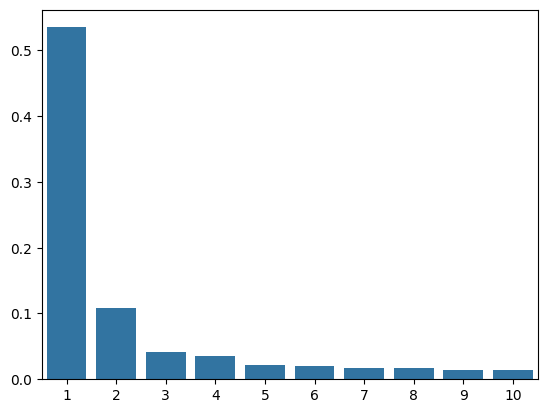

In [21]:
plt.figure()
sns.barplot(x = np.arange(1,11),y = pca.explained_variance_ratio_[:10])

RuntimeError: a Tensor with 2 elements cannot be converted to Scalar

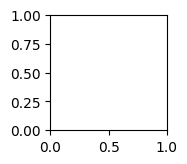

In [8]:

pca = PCA().fit(response_matrix_train.reshape(-1,response_matrix_train.shape[3]))
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
#
rows = []
for trial in range(100):
    for condition in range(response_matrix_train.shape[1]):
        trajectory = pca.transform(response_matrix_train[trial,condition,:])
        for t in range(response_matrix_train.shape[2]):
            rows.append({
            "trial":trial,
            "condition": condition_matrix_train[trial,condition,:].item(),
            't':t,
            'x': trajectory[t,0],
            'y': trajectory[t,1],})

df = pd.DataFrame(rows)
sns.scatterplot(data =df,x='x',y='y', color='gray',alpha = .1,lw=0,ax=ax,s=1)
#sns.scatterplot(data =df,x='x',y='y', hue='condition',alpha = .1,lw=0,ax=ax,s=1,legend=False,palette = 'coolwarm')
# sns.scatterplot(data =df[(df.t>10) & (df.t<20)],x='x',y='y', hue='condition',alpha = .5,lw=0,ax=ax,s=1,legend=False,palette = 'coolwarm')
#
# sns.scatterplot(data =df[(df.t>40) & (df.t<50)],x='x',y='y', hue='condition',alpha = .5,lw=0,ax=ax,s=1,legend=False,palette = 'coolwarm')

#
# for i in range(condition_matrix_train.shape[1]):
#
#     trajectory = pca.transform(torch.mean(response_matrix_train[:,i,:,],axis=0))
#     ax.plot(trajectory[:,0], trajectory[:,1], color='k',alpha = .5,lw=.5)
    #
# for condition in range(mean_responses_train.shape[0]):
#     trajectory = pca.transform(mean_responses_train[condition,:])
#     ax.plot(trajectory[:,0], trajectory[:,1],lw=.5,alpha = .5)

# predictions = linear_model.observation_layer(linear_model(mean_conditions, 100)[:,:,:latent_dim]).detach().numpy()
# for i in range(condition_matrix_train.shape[1]):
#     trajectory = pca.transform(predictions[i,:,:])
#     ax.plot(trajectory[:,0], trajectory[:,1],alpha = .5,lw=.5,color='red')
mean_responses = torch.mean(response_matrix_train,axis=0)
rows = []
for condition in range(mean_responses.shape[0]):
    trajectory = mean_responses[condition,:]
   # predicted_trajectory = linear_model.observation_layer(linear_model(mean_conditions[None,condition,:], 100)[:,:,:latent_dim]).detach().numpy().squeeze()
    proj_trajectory = pca.transform(trajectory)
    for t in range(mean_responses.shape[1]):
     #   d = np.linalg.norm(trajectory[t,:] - predicted_trajectory[t,:])
        rows.append({"condition": mean_conditions[condition,:].item(),
                     't':t,
                     'x': proj_trajectory[t,0],
                     'y': proj_trajectory[t,1],})
df = pd.DataFrame(rows)
sns.scatterplot(data = df[(df.t>30) & (df.t<60)],x = 'x',y='y',hue = 'condition',s=2,ax = ax,legend=False,lw=0,palette = 'coolwarm')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


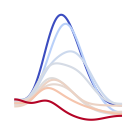

In [89]:

pca = PCA().fit(response_matrix_train.reshape(-1,response_matrix_train.shape[3]))
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sorted_neurons = np.argsort(torch.mean(torch.std(response_matrix_train,axis = 0),axis=(0,1)))

idx = 21
neuron = sorted_neurons[idx]
rows = []
for condition in range(mean_responses.shape[0]):
    trajectory = mean_responses[condition,:]
   # predicted_trajectory = linear_model.observation_layer(linear_model(mean_conditions[None,condition,:], 100)[:,:,:latent_dim]).detach().numpy().squeeze()
    proj_trajectory = pca.transform(trajectory)
    for t in range(mean_responses.shape[1]):
     #   d = np.linalg.norm(trajectory[t,:] - predicted_trajectory[t,:])
        rows.append({"condition": mean_conditions[condition,:].item(),
                     't':t,
                     'x': trajectory[t,neuron].item(),
})
sns.lineplot(data = pd.DataFrame(rows),x = 't',y='x',hue = 'condition',ax = ax,legend=False,lw=1.5,palette = 'coolwarm')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


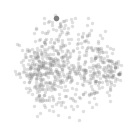

In [90]:

fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])



# kmeans= KMeans(n_clusters = 5)
# kmeans.fit(x_proj)
#


responses = torch.mean(response_matrix_train, dim=0).reshape(-1,response_matrix_train.shape[3])

# pca = PCA(n_components = 2)
# pca.fit(responses)
# responses = pca.inverse_transform(pca.transform(responses))
pca = PCA(n_components = 3)
x_proj = pca.fit_transform(responses.T)
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1], color='gray',s=6,ax=ax,legend = False,lw = 0,alpha = .25)
# sns.scatterplot(x=x_proj[sorted_neurons[:50],0], y=x_proj[sorted_neurons[:50],1], color='gray',s=6,ax=ax,legend = False,lw = 0,alpha = 1)



sns.scatterplot(x=x_proj[None,sorted_neurons[idx].item(),0], y=x_proj[None,sorted_neurons[idx].item(),1], color='gray',s=16,ax=ax,legend = False,lw = 0)
#sns.kdeplot(x=x_proj[:,0], y=x_proj[:,1], color='gray',ax=ax,fill=True,alpha = .75)


# Transform the test data using the fitted model
#X_test_lda = lda.transform(X_test)

#ax.scatter(centers[:,0], centers[:,1], alpha = 1,s=3)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_c.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

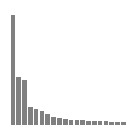

In [115]:
pca = PCA().fit(mean_responses.reshape(-1,mean_responses.shape[2]).T)
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])

sns.barplot(x=np.arange(1,21), y= pca.explained_variance_ratio_[:20],ax=ax,color='gray')

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_c.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [408]:
sorted_neurons[None,None,1].shape

torch.Size([1, 1])

<Axes: >

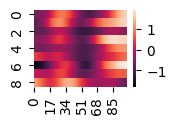

In [409]:
plt.figure(figsize=(1.5,1))
sns.heatmap(mean_responses[:,:,0])

<Axes: >

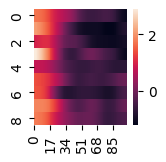

In [410]:
plt.figure(figsize=(1.5,1.5))
sns.heatmap(mean_responses[:,:,1])

<Axes: >

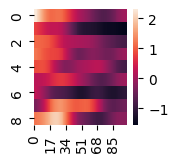

In [411]:
plt.figure(figsize=(1.5,1.5))
sns.heatmap(mean_responses[:,:,2])

<Axes: >

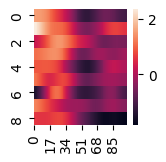

In [412]:
plt.figure(figsize=(1.5,1.5))
sns.heatmap(mean_responses[:,:,3])

<Axes: >

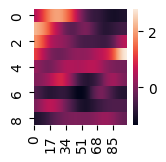

In [413]:
plt.figure(figsize=(1.5,1.5))
sns.heatmap(mean_responses[:,:,4])

<Axes: >

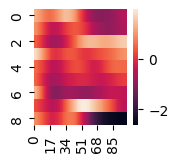

In [414]:
plt.figure(figsize=(1.5,1.5))
sns.heatmap(mean_responses[:,:,5])

<Axes: >

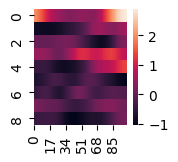

In [415]:
plt.figure(figsize=(1.5,1.5))
sns.heatmap(mean_responses[:,:,6])

<Axes: >

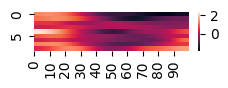

In [416]:
plt.figure(figsize=(2.5,.5))
sns.heatmap(mean_responses[:,:,7])

<Axes: >

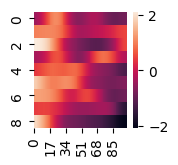

In [417]:
plt.figure(figsize=(1.5,1.5))
sns.heatmap(mean_responses[:,:,8])

<Axes: >

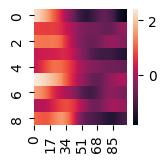

In [418]:
plt.figure(figsize=(1.5,1.5))
sns.heatmap(mean_responses[:,:,9])

In [419]:
response_matrix_train.shape

torch.Size([500, 9, 100, 791])

In [420]:
# Compute variance for each neuron,time,condition
torch.std(response_matrix_train,axis = 0)

tensor([[[7.8383e-01, 7.1230e-01, 1.3562e+00,  ..., 9.1279e-01,
          7.4643e-02, 3.0096e-01],
         [7.7840e-01, 7.0866e-01, 1.3448e+00,  ..., 9.0738e-01,
          7.7330e-02, 3.0340e-01],
         [7.6779e-01, 7.0155e-01, 1.3223e+00,  ..., 8.9677e-01,
          8.2677e-02, 3.0816e-01],
         ...,
         [1.0244e+00, 4.6377e-01, 8.7222e-01,  ..., 9.7559e-01,
          9.3285e-01, 5.5043e-01],
         [1.0323e+00, 4.6162e-01, 8.7936e-01,  ..., 9.8663e-01,
          9.4781e-01, 5.5191e-01],
         [1.0362e+00, 4.6052e-01, 8.8302e-01,  ..., 9.9222e-01,
          9.5538e-01, 5.5276e-01]],

        [[6.7876e-01, 7.4145e-01, 8.0139e-01,  ..., 9.8323e-01,
          4.8921e-02, 8.2015e-02],
         [6.7445e-01, 7.3523e-01, 7.9562e-01,  ..., 9.8168e-01,
          5.0895e-02, 8.4836e-02],
         [6.6605e-01, 7.2305e-01, 7.8427e-01,  ..., 9.7862e-01,
          5.4839e-02, 9.0477e-02],
         ...,
         [7.9636e-01, 4.9989e-01, 3.2025e-01,  ..., 7.4900e-01,
          8.642

<Axes: xlabel='None', ylabel='Count'>

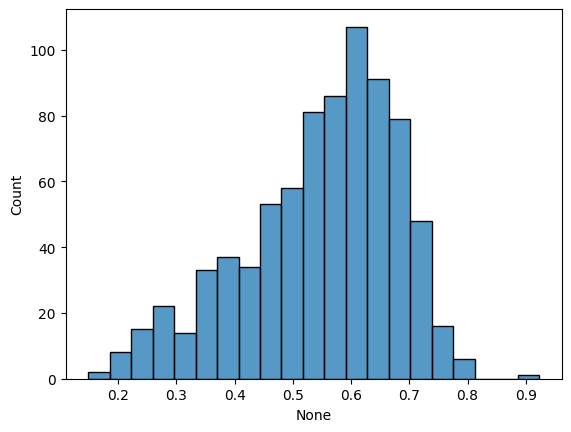

In [421]:
# Mean variance for each neuron

plt.figure()
sns.histplot(x = torch.mean(torch.std(response_matrix_train,axis = 0),axis=(0,1)))

In [422]:
torch.sum(torch.mean(torch.std(response_matrix_train,axis = 0),axis=(0,1))<.5)

tensor(240)

In [423]:
sorted_neurons = np.argsort(torch.mean(torch.std(response_matrix_train,axis = 0),axis=(0,1)))

In [424]:
pca = PCA().fit(response_matrix_train.reshape(-1,response_matrix_train.shape[3]))

<Axes: >

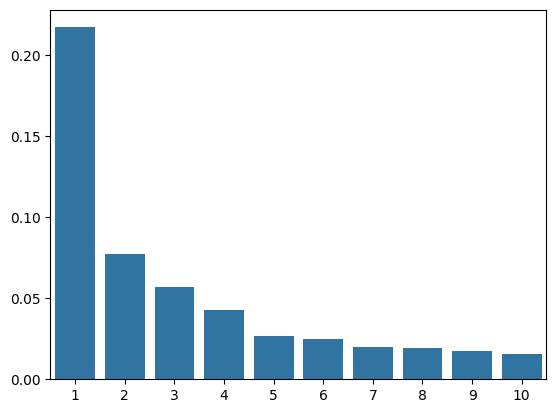

In [425]:
plt.figure()
sns.barplot(x = np.arange(1,11), y= pca.explained_variance_ratio_[:10])